# E-commerce Customer Journey Analytics.

### A session- and customer-level investigation of e-commerce behaviour

**Python · Pandas · NumPy · Matplotlib · Seaborn · SciPy · SQL**

## Executive question
Where does the customer journey lose momentum, which observable customer and session characteristics are associated with purchase, and what should an e-commerce team investigate next?

**Dataset caveat:** The supplied dataset appears synthetic. Results are useful for demonstrating analytical methods, not for setting real-world e-commerce benchmarks or claiming causal explanations.

## Analysis plan

Rather than only reporting a basic funnel, this notebook examines six connected questions:

1. **Journey integrity:** Are events in a plausible order, and do session-level attributes remain consistent?
2. **Journey friction:** At which transition are the largest numbers and proportions of sessions lost?
3. **Customer context:** How do country, device, referral source and calendar month relate to purchase?
4. **Engagement signals:** How do recorded page time, journey length and cart activity differ by purchase outcome?
5. **Repeat-customer behaviour:** Do later observed sessions behave differently from a user's first recorded session?
6. **Decision framework:** Which hypotheses deserve testing, what should be measured, and what cannot be concluded from this data?

The analysis uses **session** as the main unit for conversion. Event rows are used only for event-level and stage-reach questions.

## 1. Set up the analysis

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = Path("funnel-drop-data.csv")
FUNNEL = ["home", "product_page", "cart", "checkout", "confirmation"]
ALPHA = 0.05

## 2. Load and understand the raw events

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Place {DATA_PATH.name} in the same folder as this notebook.")

events_raw = pd.read_csv(DATA_PATH)
events = events_raw.copy()
print(f"Dataset shape: {events.shape[0]:,} event rows × {events.shape[1]} columns")
display(events.head())
display(pd.DataFrame({
    "dtype": events.dtypes.astype(str),
    "missing": events.isna().sum(),
    "unique": events.nunique()
}))

Dataset shape: 12,719 event rows × 10 columns


,SessionID,UserID,Timestamp,PageType,DeviceType,Country,ReferralSource,TimeOnPage_seconds,ItemsInCart,Purchased
0,session_0,user_2223,2025-01-20 22:53:34,home,Desktop,India,Social Media,55,0,0
1,session_1,user_2192,2025-02-26 12:57:10,home,Tablet,Germany,Email,99,0,0
2,session_1,user_2192,2025-02-26 12:59:11,product_page,Tablet,Germany,Email,121,0,0
3,session_2,user_1708,2025-06-24 15:40:46,home,Mobile,India,Google,160,0,0
4,session_3,user_2976,2025-06-11 07:21:02,home,Tablet,UK,Google,113,0,0


,dtype,missing,unique
SessionID,object,0,5000
UserID,object,0,1872
Timestamp,object,0,12713
PageType,object,0,5
DeviceType,object,0,3
Country,object,0,7
ReferralSource,object,0,4
TimeOnPage_seconds,int64,0,166
ItemsInCart,int64,0,6
Purchased,int64,0,2


## 3. Clean fields and audit data quality

In [3]:
events["Timestamp"] = pd.to_datetime(events["Timestamp"], errors="coerce")
text_columns = ["SessionID", "UserID", "PageType", "DeviceType", "Country", "ReferralSource"]
for col in text_columns:
    events[col] = events[col].astype("string").str.strip()
events["PageType"] = events["PageType"].str.lower()

for col in ["TimeOnPage_seconds", "ItemsInCart", "Purchased"]:
    events[col] = pd.to_numeric(events[col], errors="coerce")

audit = pd.Series({
    "duplicate_event_rows": int(events.duplicated().sum()),
    "missing_cells": int(events.isna().sum().sum()),
    "missing_session_ids": int(events["SessionID"].isna().sum()),
    "invalid_timestamps": int(events["Timestamp"].isna().sum()),
    "unknown_page_types": int((~events["PageType"].isin(FUNNEL)).sum()),
    "invalid_purchase_flags": int((~events["Purchased"].isin([0, 1])).sum()),
    "negative_page_time": int((events["TimeOnPage_seconds"] < 0).sum()),
    "negative_cart_count": int((events["ItemsInCart"] < 0).sum())
}, name="issue_count")
display(audit.to_frame())

if events[["SessionID", "UserID", "Timestamp", "PageType", "Purchased"]].isna().any().any():
    raise ValueError("Essential fields are missing or invalid; inspect the audit before continuing.")
if (~events["PageType"].isin(FUNNEL)).any() or (~events["Purchased"].isin([0, 1])).any():
    raise ValueError("Unexpected page or purchase values found.")

,issue_count
duplicate_event_rows,0
missing_cells,0
missing_session_ids,0
invalid_timestamps,0
unknown_page_types,0
invalid_purchase_flags,0
negative_page_time,0
negative_cart_count,0


## 4. Construct one record per session

In [4]:
events = events.sort_values(["SessionID", "Timestamp"]).reset_index(drop=True)

session = (
    events.groupby("SessionID", as_index=False)
    .agg(
        UserID=("UserID", "first"),
        Device=("DeviceType", "first"),
        Country=("Country", "first"),
        AcquisitionSource=("ReferralSource", "first"),
        Start=("Timestamp", "min"),
        End=("Timestamp", "max"),
        Purchased=("Purchased", "max"),
        MaxCartItems=("ItemsInCart", "max"),
        EventRows=("PageType", "size"),
        Journey=("PageType", list),
        PageTimeTotal=("TimeOnPage_seconds", "sum")
    )
)
session["ElapsedSeconds"] = (session["End"] - session["Start"]).dt.total_seconds()
session["JourneyDepth"] = session["Journey"].map(len)
session["StartMonth"] = session["Start"].dt.to_period("M").astype(str)
session["StartHour"] = session["Start"].dt.hour
session["StartWeekday"] = session["Start"].dt.day_name()

print(f"Events: {len(events):,} | Sessions: {len(session):,} | Users: {session['UserID'].nunique():,}")
display(session.head())

Events: 12,719 | Sessions: 5,000 | Users: 1,872


,SessionID,UserID,Device,Country,AcquisitionSource,Start,End,Purchased,MaxCartItems,EventRows,Journey,PageTimeTotal,ElapsedSeconds,JourneyDepth,StartMonth,StartHour,StartWeekday
0,session_0,user_2223,Desktop,India,Social Media,2025-01-20 22:53:34,2025-01-20 22:53:34,0,0,1,[home],55,0.00,1,2025-01,22,Monday
1,session_1,user_2192,Tablet,Germany,Email,2025-02-26 12:57:10,2025-02-26 12:59:11,0,0,2,"[home, product_page]",220,121.00,2,2025-02,12,Wednesday
2,session_10,user_2357,Tablet,India,Direct,2025-05-17 22:11:37,2025-05-17 22:13:33,0,0,2,"[home, product_page]",191,116.00,2,2025-05,22,Saturday
3,session_100,user_1233,Desktop,USA,Email,2025-04-02 11:24:36,2025-04-02 11:25:41,0,1,2,"[home, product_page]",101,65.00,2,2025-04,11,Wednesday
4,session_1000,user_1551,Mobile,France,Email,2025-08-25 09:34:15,2025-08-25 09:41:24,1,3,5,"[home, product_page, cart, checkout, confirmat...",474,429.00,5,2025-08,9,Monday


## 5. Validate journey order and session attributes

In [5]:
rank = {stage: i for i, stage in enumerate(FUNNEL)}
journey_audit = []
for sid, group in events.groupby("SessionID", sort=False):
    pages = group["PageType"].tolist()
    ranks = [rank[p] for p in pages]
    journey_audit.append({
        "SessionID": sid,
        "begins_home": pages[0] == "home",
        "stage_order_valid": ranks == sorted(ranks),
        "no_duplicate_stage": len(pages) == len(set(pages)),
        "purchase_matches_confirmation":
            (group["Purchased"].max() == 1) == ("confirmation" in pages)
    })
journey_audit = pd.DataFrame(journey_audit)
display((journey_audit.drop(columns="SessionID").mean()*100).round(2).rename("pass_rate_pct").to_frame())

attribute_consistency = events.groupby("SessionID")[["UserID","DeviceType","Country","ReferralSource"]].nunique()
inconsistent = (attribute_consistency > 1).any(axis=1).sum()
print(f"Sessions with inconsistent customer/session attributes: {inconsistent:,}")

# Journey stages reached by each session
for stage in FUNNEL:
    session[f"Reached_{stage}"] = session["Journey"].map(lambda journey: stage in journey)

,pass_rate_pct
begins_home,100.00
stage_order_valid,100.00
no_duplicate_stage,100.00
purchase_matches_confirmation,100.00


Sessions with inconsistent customer/session attributes: 0


## 6. Journey progression: reach, conversion and loss

In [6]:
journey_table = pd.DataFrame(index=FUNNEL)
journey_table["sessions_reached"] = [
    session[f"Reached_{stage}"].sum() for stage in FUNNEL
]
journey_table["reach_rate_from_home_pct"] = (
    journey_table["sessions_reached"] / len(session) * 100
)
journey_table["next_stage_sessions"] = journey_table["sessions_reached"].shift(-1)
journey_table["transition_loss_sessions"] = (
    journey_table["sessions_reached"] - journey_table["next_stage_sessions"]
)
journey_table["transition_loss_pct"] = (
    journey_table["transition_loss_sessions"] / journey_table["sessions_reached"] * 100
)
journey_table.loc["confirmation", ["next_stage_sessions","transition_loss_sessions","transition_loss_pct"]] = np.nan
journey_table["step_through_rate_pct"] = (
    journey_table["next_stage_sessions"] / journey_table["sessions_reached"] * 100
)
display(journey_table.round(2))

overall_buyers = int(session["Purchased"].sum())
overall_rate = session["Purchased"].mean()*100
print(f"Session purchase rate: {overall_rate:.2f}% ({overall_buyers:,} of {len(session):,} sessions)")

,sessions_reached,reach_rate_from_home_pct,next_stage_sessions,transition_loss_sessions,transition_loss_pct,step_through_rate_pct
home,5000,100.00,"3,987.00","1,013.00",20.26,79.74
product_page,3987,79.74,"1,599.00","2,388.00",59.89,40.11
cart,1599,31.98,"1,123.00",476.00,29.77,70.23
checkout,1123,22.46,"1,010.00",113.00,10.06,89.94
confirmation,1010,20.20,NaN,NaN,NaN,NaN


Session purchase rate: 20.20% (1,010 of 5,000 sessions)


## 7. Visualise the journey and locate the largest friction point

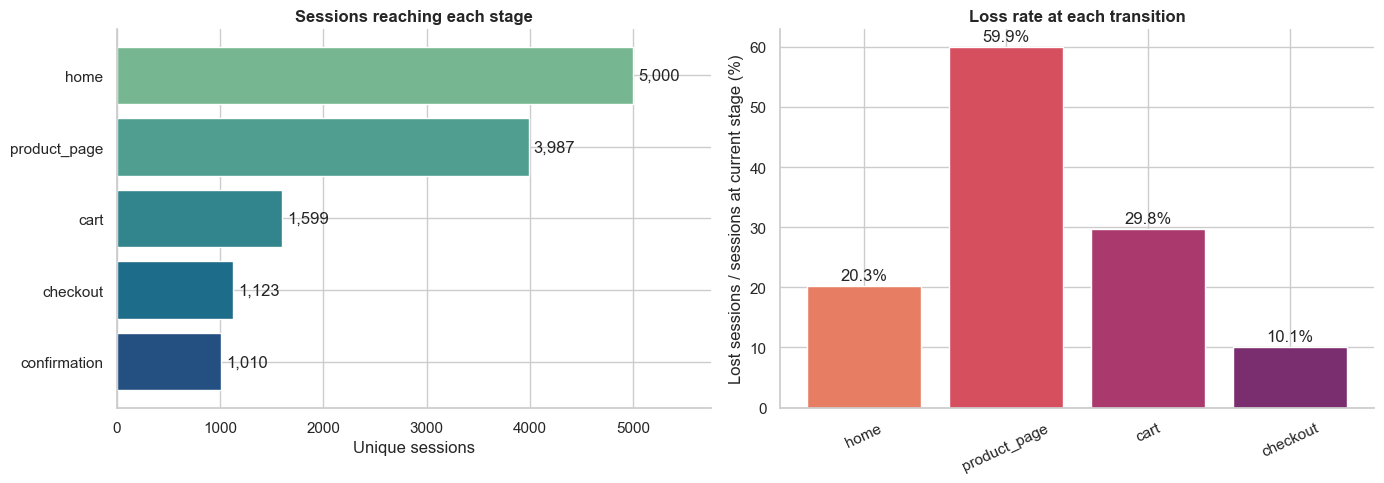

Largest absolute loss: product_page → cart: 2,388 sessions (59.9%).


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
reach = journey_table["sessions_reached"]
axes[0].barh(FUNNEL, reach, color=sns.color_palette("crest", len(FUNNEL)))
axes[0].invert_yaxis()
axes[0].set_title("Sessions reaching each stage", weight="bold")
axes[0].set_xlabel("Unique sessions")
for y, value in enumerate(reach):
    axes[0].text(value + len(session)*.01, y, f"{int(value):,}", va="center")
axes[0].set_xlim(0, len(session)*1.15)

loss = journey_table["transition_loss_pct"].dropna()
axes[1].bar(loss.index, loss.values, color=sns.color_palette("flare", len(loss)))
axes[1].set_title("Loss rate at each transition", weight="bold")
axes[1].set_ylabel("Lost sessions / sessions at current stage (%)")
axes[1].tick_params(axis="x", rotation=25)
for i, value in enumerate(loss):
    axes[1].text(i, value+1, f"{value:.1f}%", ha="center")
sns.despine()
plt.tight_layout()
plt.show()

largest_stage = journey_table["transition_loss_sessions"].dropna().idxmax()
largest_next = FUNNEL[FUNNEL.index(largest_stage)+1]
largest_n = int(journey_table.loc[largest_stage, "transition_loss_sessions"])
largest_pct = float(journey_table.loc[largest_stage, "transition_loss_pct"])
print(f"Largest absolute loss: {largest_stage} → {largest_next}: {largest_n:,} sessions ({largest_pct:.1f}%).")

## 8. Segment scorecard: device, source and country

In [8]:
def segment_score(data, dimension):
    out = data.groupby(dimension)["Purchased"].agg(
        sessions="size", purchases="sum", conversion="mean"
    )
    out["conversion_pct"] = out["conversion"]*100
    out["share_of_sessions_pct"] = out["sessions"]/len(data)*100
    return out.drop(columns="conversion").sort_values("conversion_pct", ascending=False)

device_score = segment_score(session, "Device")
source_score = segment_score(session, "AcquisitionSource")
country_score = segment_score(session, "Country")

print("DEVICE")
display(device_score.round(2))
print("ACQUISITION SOURCE")
display(source_score.round(2))
print("COUNTRY")
display(country_score.round(2))

DEVICE


,sessions,purchases,conversion_pct,share_of_sessions_pct
Device,,,,
Desktop,1666,339,20.35,33.32
Mobile,1671,337,20.17,33.42
Tablet,1663,334,20.08,33.26


ACQUISITION SOURCE


,sessions,purchases,conversion_pct,share_of_sessions_pct
AcquisitionSource,,,,
Google,1280,277,21.64,25.60
Email,1251,251,20.06,25.02
Direct,1226,243,19.82,24.52
Social Media,1243,239,19.23,24.86


COUNTRY


,sessions,purchases,conversion_pct,share_of_sessions_pct
Country,,,,
France,752,170,22.61,15.04
USA,706,147,20.82,14.12
India,702,145,20.66,14.04
UK,739,145,19.62,14.78
Canada,715,140,19.58,14.30
Australia,683,131,19.18,13.66
Germany,703,132,18.78,14.06


## 9. Compare segment conversion visually

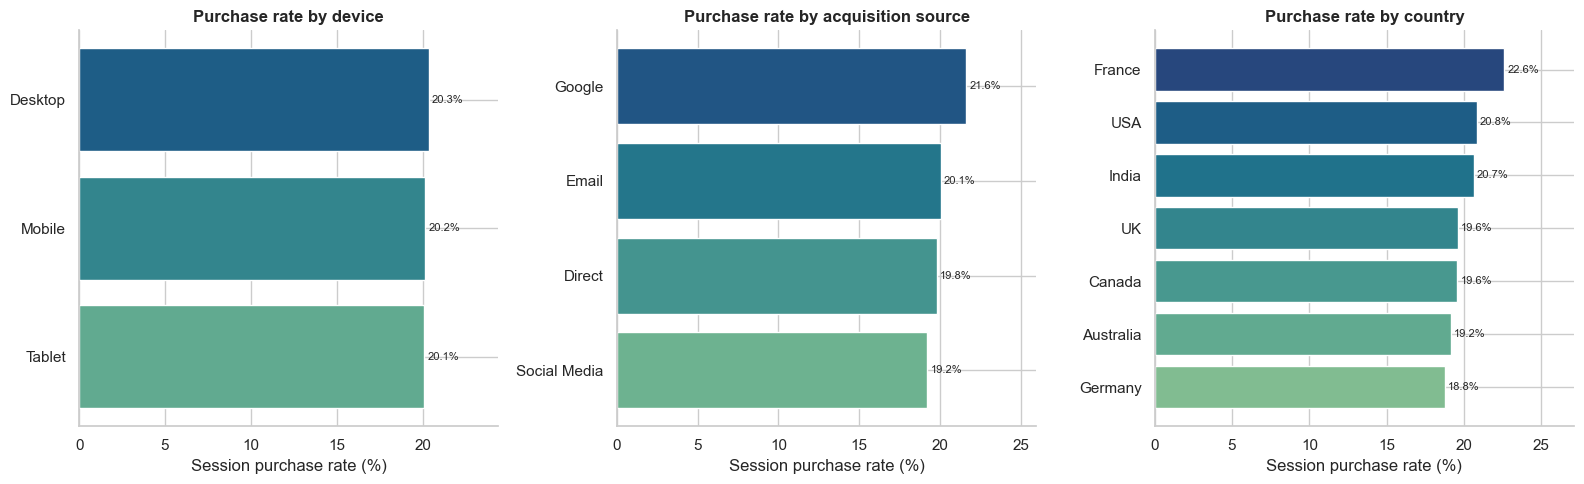

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, table, title in [
    (axes[0], device_score, "Purchase rate by device"),
    (axes[1], source_score, "Purchase rate by acquisition source"),
    (axes[2], country_score, "Purchase rate by country")
]:
    vals = table.sort_values("conversion_pct")
    ax.barh(vals.index, vals["conversion_pct"], color=sns.color_palette("crest", len(vals)))
    ax.set_title(title, weight="bold")
    ax.set_xlabel("Session purchase rate (%)")
    for y, v in enumerate(vals["conversion_pct"]):
        ax.text(v+.2, y, f"{v:.1f}%", va="center", fontsize=8)
    ax.set_xlim(0, max(vals["conversion_pct"])*1.2)
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## 10. Statistical association tests with effect size

In [10]:
def cramers_v(table):
    chi2_stat, _, _, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    r, k = table.shape
    denom = n * min(r-1, k-1)
    return np.sqrt(chi2_stat/denom) if denom > 0 else np.nan

def test_segment_association(data, column):
    table = pd.crosstab(data[column], data["Purchased"])
    chi2_stat, p_value, dof, expected = chi2_contingency(table)
    result = {
        "dimension": column,
        "chi_square": chi2_stat,
        "degrees_freedom": dof,
        "p_value": p_value,
        "cramers_v": cramers_v(table),
        "min_expected_cell": expected.min()
    }
    return result, table

test_results = []
for col in ["Device", "AcquisitionSource", "Country"]:
    result, tab = test_segment_association(session, col)
    test_results.append(result)
    print(f"\n{col}")
    display(tab)
tests_df = pd.DataFrame(test_results)
display(tests_df.round(4))
print("Interpretation: p < 0.05 indicates evidence of association in this sample, not a causal effect. "
      "Cramér's V describes association strength. Small expected cell counts warrant caution.")


Device


Purchased,0,1
Device,,
Desktop,1327,339
Mobile,1334,337
Tablet,1329,334



AcquisitionSource


Purchased,0,1
AcquisitionSource,,
Direct,983,243
Email,1000,251
Google,1003,277
Social Media,1004,239



Country


Purchased,0,1
Country,,
Australia,552,131
Canada,575,140
France,582,170
Germany,571,132
India,557,145
UK,594,145
USA,559,147


,dimension,chi_square,degrees_freedom,p_value,cramers_v,min_expected_cell
0,Device,0.04,2,0.98,0.00,335.93
1,AcquisitionSource,2.50,3,0.48,0.02,247.65
2,Country,4.61,6,0.59,0.03,137.97


Interpretation: p < 0.05 indicates evidence of association in this sample, not a causal effect. Cramér's V describes association strength. Small expected cell counts warrant caution.


## 11. Calendar pattern: monthly purchase rate

,sessions,purchases,purchase_rate,purchase_rate_pct
StartMonth,,,,
2025-01,657,126,0.19,19.18
2025-02,593,110,0.18,18.55
2025-03,630,135,0.21,21.43
2025-04,564,118,0.21,20.92
2025-05,634,129,0.20,20.35
2025-06,630,128,0.20,20.32
2025-07,656,133,0.20,20.27
2025-08,636,131,0.21,20.60


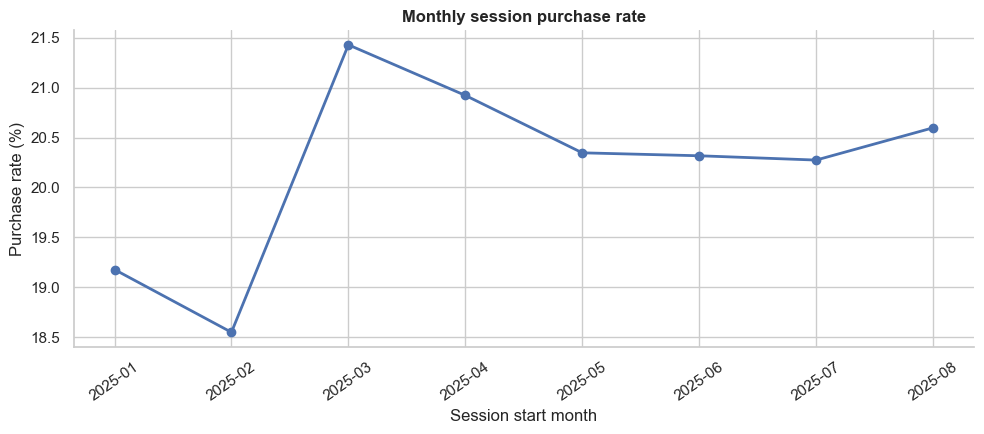

In [11]:
monthly = session.groupby("StartMonth")["Purchased"].agg(
    sessions="size", purchases="sum", purchase_rate="mean"
)
monthly["purchase_rate_pct"] = monthly["purchase_rate"]*100
display(monthly.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly.index, monthly["purchase_rate_pct"], marker="o", linewidth=2)
ax.set_title("Monthly session purchase rate", weight="bold")
ax.set_xlabel("Session start month")
ax.set_ylabel("Purchase rate (%)")
ax.tick_params(axis="x", rotation=35)
sns.despine()
plt.tight_layout()
plt.show()

## 12. Engagement profile: what differs between purchased and non-purchased sessions?

In [12]:
engagement = session.groupby("Purchased").agg(
    sessions=("SessionID","size"),
    median_elapsed_seconds=("ElapsedSeconds","median"),
    median_recorded_page_time=("PageTimeTotal","median"),
    median_journey_depth=("JourneyDepth","median"),
    median_max_cart_items=("MaxCartItems","median")
)
display(engagement.rename(index={0:"No purchase",1:"Purchase"}).round(2))

,sessions,median_elapsed_seconds,median_recorded_page_time,median_journey_depth,median_max_cart_items
Purchased,,,,,
No purchase,3990,81.00,179.00,2.00,0.00
Purchase,1010,389.00,483.50,5.00,3.00


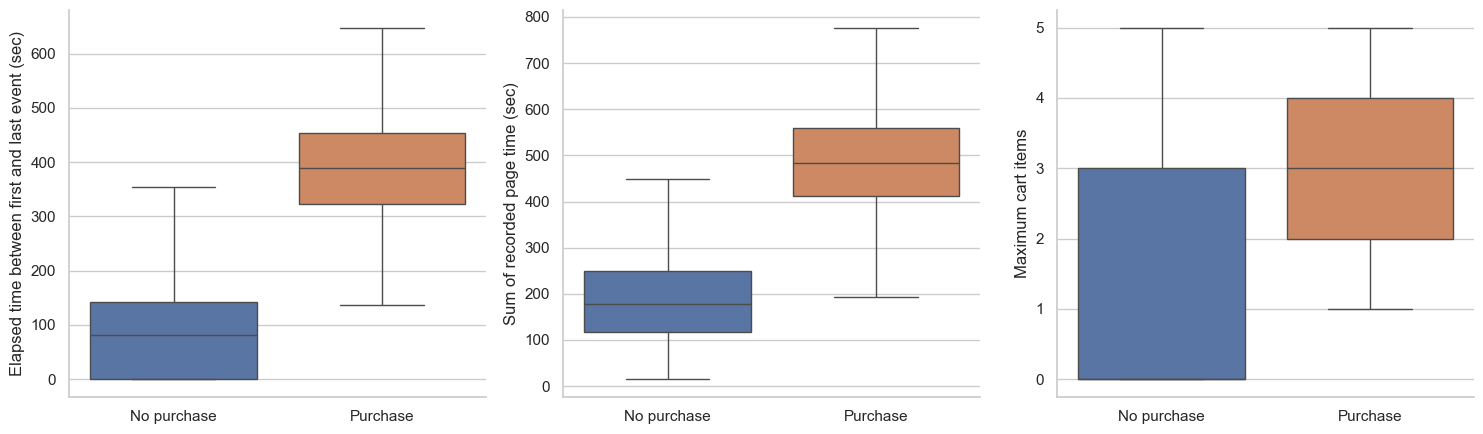

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_specs = [
    ("ElapsedSeconds", "Elapsed time between first and last event (sec)"),
    ("PageTimeTotal", "Sum of recorded page time (sec)"),
    ("MaxCartItems", "Maximum cart items")
]
for ax, (col, label) in zip(axes, plot_specs):
    sns.boxplot(data=session, x="Purchased", y=col, hue="Purchased",
                legend=False, showfliers=False, ax=ax)
    ax.set_xticks([0,1], ["No purchase","Purchase"])
    ax.set_xlabel("")
    ax.set_ylabel(label)
sns.despine()
plt.tight_layout()
plt.show()

## 13. Page-level engagement profile

,event_rows,mean_seconds,median_seconds,p25_seconds,p75_seconds
PageType,,,,,
home,5000,97.79,98.00,56.75,138.00
product_page,3987,97.06,98.00,55.00,139.00
cart,1599,98.74,99.00,56.00,141.00
checkout,1123,96.61,98.00,55.00,139.50
confirmation,1010,95.92,97.00,52.00,137.00


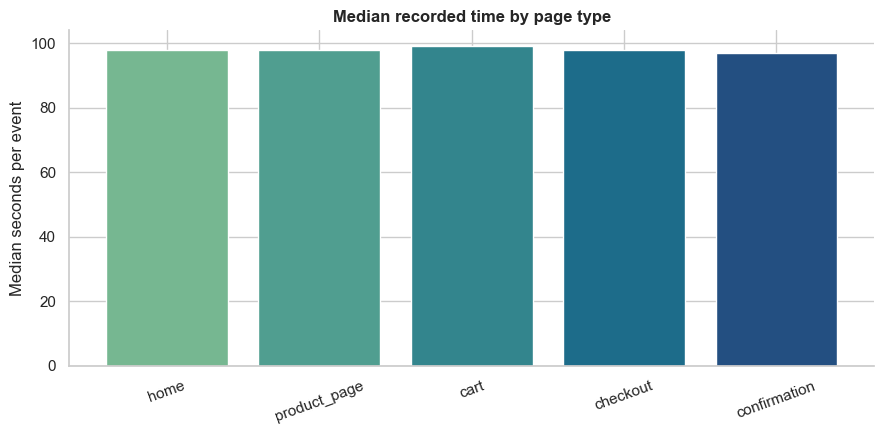

In [14]:
page_profile = events.groupby("PageType")["TimeOnPage_seconds"].agg(
    event_rows="size", mean_seconds="mean", median_seconds="median",
    p25_seconds=lambda x: x.quantile(.25), p75_seconds=lambda x: x.quantile(.75)
).reindex(FUNNEL)
display(page_profile.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(page_profile.index, page_profile["median_seconds"],
       color=sns.color_palette("crest", len(page_profile)))
ax.set_title("Median recorded time by page type", weight="bold")
ax.set_ylabel("Median seconds per event")
ax.tick_params(axis="x", rotation=20)
sns.despine()
plt.tight_layout()
plt.show()

## 14. Cart behaviour and conversion

,sessions,purchases,purchase_rate_pct
MaxCartItems,,,
0,2088,0,0.00
1,568,214,37.68
2,569,197,34.62
3,668,255,38.17
4,561,175,31.19
5,546,169,30.95


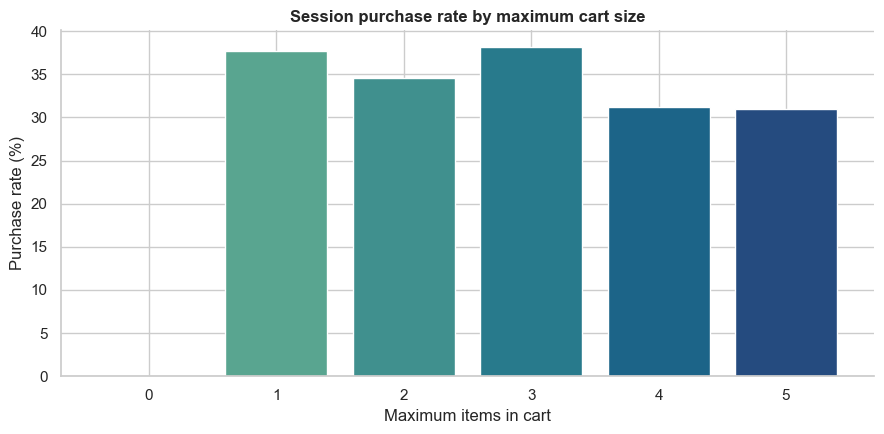

In [15]:
cart_profile = session.groupby("MaxCartItems")["Purchased"].agg(
    sessions="size", purchases="sum", purchase_rate="mean"
)
cart_profile["purchase_rate_pct"] = cart_profile["purchase_rate"]*100
display(cart_profile.drop(columns="purchase_rate").round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(cart_profile.index.astype(str), cart_profile["purchase_rate_pct"],
       color=sns.color_palette("crest", len(cart_profile)))
ax.set_title("Session purchase rate by maximum cart size", weight="bold")
ax.set_xlabel("Maximum items in cart")
ax.set_ylabel("Purchase rate (%)")
sns.despine()
plt.tight_layout()
plt.show()

## 15. Returning-user lens

In [16]:
# Order sessions chronologically within each user. This is the first observed session in this dataset,
# not necessarily the user's first-ever interaction with the store.
session = session.sort_values(["UserID","Start"]).copy()
session["ObservedSessionNumber"] = session.groupby("UserID").cumcount()+1
session["SessionType"] = np.where(session["ObservedSessionNumber"] == 1,
                                  "First observed session", "Later observed session")

repeat_summary = session.groupby("SessionType")["Purchased"].agg(
    sessions="size", purchases="sum", purchase_rate="mean"
)
repeat_summary["purchase_rate_pct"] = repeat_summary["purchase_rate"]*100
display(repeat_summary.drop(columns="purchase_rate").round(2))

user_summary = session.groupby("UserID").agg(
    observed_sessions=("SessionID","size"),
    sessions_with_purchase=("Purchased","sum"),
    ever_purchased=("Purchased","max")
)
print(f"Users represented: {len(user_summary):,}")
print(f"Users with more than one observed session: {(user_summary['observed_sessions']>1).sum():,}")
display(user_summary["observed_sessions"].value_counts().sort_index().rename_axis("observed_sessions").to_frame("users"))

,sessions,purchases,purchase_rate_pct
SessionType,,,
First observed session,1872,353,18.86
Later observed session,3128,657,21.00


Users represented: 1,872
Users with more than one observed session: 1,433


,users
observed_sessions,
1,439
2,526
3,448
4,254
5,124
6,52
7,21
8,3
9,4


## 16. First observed session vs later session comparison

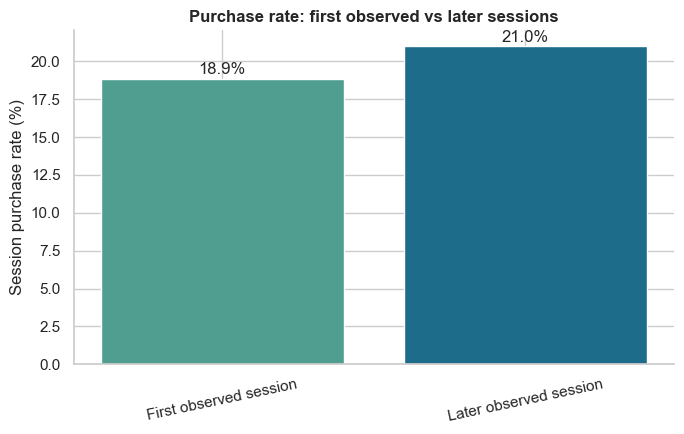

Caution: later sessions are not randomly assigned. Differences may reflect selection, customer history, or the synthetic construction of the dataset.


In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5))
vals = repeat_summary["purchase_rate_pct"]
ax.bar(vals.index, vals.values, color=sns.color_palette("crest", len(vals)))
ax.set_title("Purchase rate: first observed vs later sessions", weight="bold")
ax.set_ylabel("Session purchase rate (%)")
ax.tick_params(axis="x", rotation=12)
for i, v in enumerate(vals):
    ax.text(i, v+.3, f"{v:.1f}%", ha="center")
sns.despine()
plt.tight_layout()
plt.show()
print("Caution: later sessions are not randomly assigned. Differences may reflect selection, customer history, "
      "or the synthetic construction of the dataset.")

## 17. Explore when sessions start

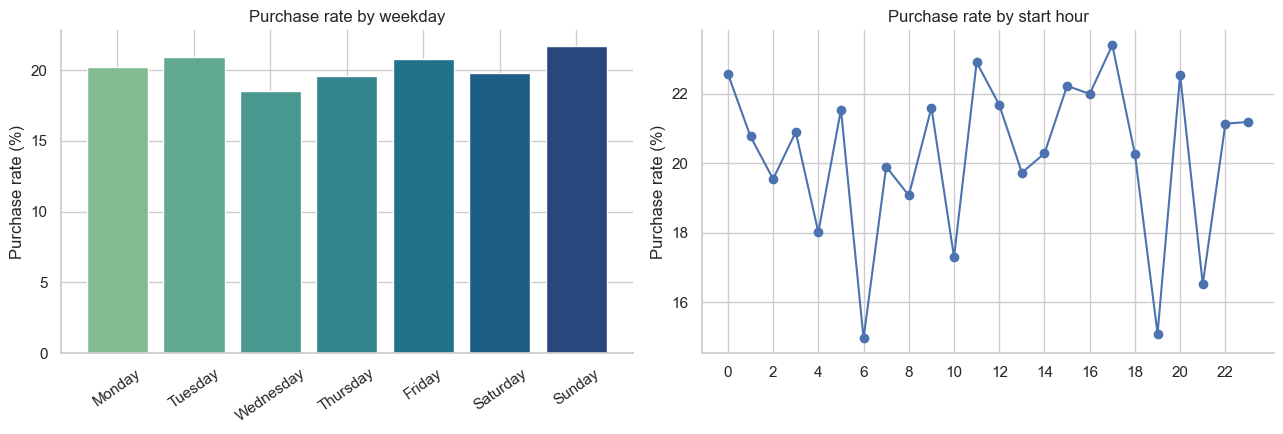

In [18]:
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday = session.groupby("StartWeekday")["Purchased"].agg(sessions="size", rate="mean").reindex(weekday_order)
hour = session.groupby("StartHour")["Purchased"].agg(sessions="size", rate="mean")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(weekday.index, weekday["rate"]*100, color=sns.color_palette("crest", 7))
axes[0].set_title("Purchase rate by weekday")
axes[0].tick_params(axis="x", rotation=35)
axes[1].plot(hour.index, hour["rate"]*100, marker="o")
axes[1].set_title("Purchase rate by start hour")
axes[1].set_xticks(range(0,24,2))
for ax in axes:
    ax.set_ylabel("Purchase rate (%)")
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## 18. Prioritise opportunities using evidence, not assumptions

In [19]:
# Create an evidence summary from calculated values.
segment_ranges = {
    "Device": device_score["conversion_pct"].max()-device_score["conversion_pct"].min(),
    "Acquisition source": source_score["conversion_pct"].max()-source_score["conversion_pct"].min(),
    "Country": country_score["conversion_pct"].max()-country_score["conversion_pct"].min()
}
print("DIAGNOSTIC SUMMARY")
print(f"Overall session purchase rate: {overall_rate:.2f}%")
print(f"Largest journey loss: {largest_stage} → {largest_next} "
      f"({largest_n:,} sessions; {largest_pct:.1f}% of sessions at that stage)")
print("\nObserved segment conversion spread (highest minus lowest):")
for k,v in segment_ranges.items():
    print(f"• {k}: {v:.2f} percentage points")
print("\nStatistical association tests:")
for _, row in tests_df.iterrows():
    print(f"• {row['dimension']}: p={row['p_value']:.4f}, Cramér's V={row['cramers_v']:.3f}")

DIAGNOSTIC SUMMARY
Overall session purchase rate: 20.20%
Largest journey loss: product_page → cart (2,388 sessions; 59.9% of sessions at that stage)

Observed segment conversion spread (highest minus lowest):
• Device: 0.26 percentage points
• Acquisition source: 2.41 percentage points
• Country: 3.83 percentage points

Statistical association tests:
• Device: p=0.9814, Cramér's V=0.003
• AcquisitionSource: p=0.4751, Cramér's V=0.022
• Country: p=0.5948, Cramér's V=0.030


## 19. Recommendations: hypotheses to validate

### Priority 1 — Investigate the largest journey loss
The largest loss identifies **where** the journey weakens, not **why**. Review the relevant page and event instrumentation. Check whether the next-step action is visible, understandable and technically reliable.

### Priority 2 — Run a controlled page experiment
Test one change at a time (for example, clearer primary action, delivery-cost visibility, product information hierarchy or trust information). Define the primary metric before launch:
- Primary: next-stage progression rate.
- Guardrails: purchase rate, refunds/cancellations if available, page performance and average order value if available.
- Segment checks: device and acquisition source, without overreacting to small samples.

### Priority 3 — Audit cart and checkout experience
Measure shipping-cost exposure, payment errors, guest checkout availability, form abandonment and delivery promise clarity. The current dataset cannot explain these mechanisms, so collect the required events first.

### Priority 4 — Understand customer return behaviour
Later observed sessions may have a different purchase rate from first observed sessions. Treat this as a descriptive signal, not proof that repeat visits cause conversion. In a real product, connect sessions to consented customer history and test relevant lifecycle interventions.

### Priority 5 — Improve measurement quality
Capture consistent timestamps, event IDs, page views, product impressions, add-to-cart clicks, cart removals, checkout starts, payment failures and purchase value. Include experiment assignment and exposure events for causal evaluation.

## 20. Limitations and what this analysis cannot tell us

- The dataset appears synthetic; regular patterns and observed rates may not reflect real e-commerce.
- It contains no product ID, price, order value, margin, promotion, shipping cost, payment outcome, page content or experiment assignment.
- A session's `Purchased` flag is treated as a session-level outcome. The data does not establish the exact causal event that triggered purchase.
- `ElapsedSeconds` is the time between first and last recorded event, not necessarily active browsing time.
- The first observed session in this file is not necessarily a customer's first-ever session.
- Chi-square tests identify evidence of association, not causality. Non-significance does not prove equivalence.
- Small segment counts and multiple comparisons can make apparent differences unstable.
- The analysis does not estimate revenue impact because order value and revenue are absent.

## 21. Final takeaway

A useful analytics project should do more than point to a low-converting step. It should separate observed facts from explanations, quantify uncertainty, expose data limitations and recommend experiments that can confirm or reject the proposed mechanisms.

**The next best step is not to assume the cause of drop-off—it is to instrument the journey well enough to test the cause.**

## Dataset source and reproducibility

Dataset: [E-Commerce Customer Journey: Click to Conversion — Kaggle](https://www.kaggle.com/datasets/sufya6/e-commerce-customer-journey-click-to-conversion)



To reproduce:
1. Keep `funnel-drop-data.csv` in the same folder as this notebook.
2. Install dependencies with `python -m pip install -r requirements.txt`.
3. Select a Python kernel in VS Code or Jupyter.
4. Run all cells from top to bottom.